# Oxford 102 Flowers — Baseline Classification Pipeline

An end-to-end baseline workflow for this dataset: problem definition → data exploration → preprocessing → transfer-learning model → training → evaluation → error analysis → next steps.

**Guiding principle:** start with a simple, solid pipeline first (pretrained CNN plus a new linear head), then add complexity in clearly marked places.

> 🧪 Cells marked **Experimentation point** are the natural places to try changes once the baseline works.

## 1. Problem Definition

**Task.** The [Oxford 102 Flowers](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/) dataset (Nilsback & Zisserman, 2008) contains photographs of 102 flower species commonly found in the UK. It is a **fine-grained image classification** problem. Many classes look alike (for example, several lilies, dahlias and poppies), and appearance within a class varies a lot with pose, scale, lighting and background.

| | |
|---|---|
| **Input** | An RGB photograph of a flower. Sizes vary, with the shorter side ≈ 500 px. |
| **Output** | One of 102 class labels, which `cat_to_name.json` maps to species names. |
| **Objective** | Learn $f: \text{image} \rightarrow \{1,\dots,102\}$ that maximises accuracy on unseen images. Macro precision, recall and F1 are also tracked because the classes are imbalanced. |

**Approach.** With only a few dozen training images per class, training a CNN from scratch would overfit badly. Instead, this notebook uses **transfer learning** from an ImageNet-pretrained network.

### 1.1 Setup & configuration

All tunable settings live in one cell. Dependencies are deliberately minimal: `torch`, `torchvision`, `numpy`, `matplotlib`, `Pillow`. Metrics are implemented with NumPy, so scikit-learn is not required.

```bash
pip install torch torchvision numpy matplotlib pillow
```

In [15]:
import copy
import csv
import json
import os
import random
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

print(f"torch {torch.__version__} | torchvision {__import__('torchvision').__version__}")

torch 2.14.1+cpu | torchvision 0.29.1+cpu


In [16]:
# ---------------- Configuration ----------------
SEED = 42

IMG_SIZE = 224            # input resolution expected by ImageNet-pretrained CNNs
BATCH_SIZE = 32
VAL_FRACTION = 0.10       # fraction of each training class held out for validation (if no labeled val split exists)

MODEL_NAME = "resnet18"   # 🧪 try "resnet50" or "efficientnet_b0"
HEAD_EPOCHS = 5           # stage 1: train only the new classifier head
FINETUNE_EPOCHS = 3       # stage 2: also unfreeze the last backbone block (set 0 to skip)
HEAD_LR = 1e-3
FINETUNE_LR = 1e-4
WEIGHT_DECAY = 1e-4

QUICK_RUN = False         # True = tiny subset + 1 epoch per stage, for a fast smoke test of the pipeline

# On Windows, DataLoader worker processes cannot import classes defined inside a notebook,
# so use 0 workers there (data loads in the main process).
NUM_WORKERS = 0 if os.name == "nt" else 4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

if QUICK_RUN:
    HEAD_EPOCHS, FINETUNE_EPOCHS = 1, 1


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
print("Device:", DEVICE)

Device: cpu


## 2. Dataset Exploration

### 2.1 Locate and inspect the dataset

The notebook makes no assumptions about the directory layout. It searches for the folder containing `cat_to_name.json` and then checks each sub-directory to see whether it is **labeled** (has one sub-folder per class) or **unlabeled** (a flat folder of images).

In [17]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def find_data_root(candidates):
    for c in candidates:
        if (c / "cat_to_name.json").exists():
            return c.resolve()
    raise FileNotFoundError(f"cat_to_name.json not found in any of: {candidates}")


def describe_split(split_dir):
    # Labeled split = one sub-folder per class; unlabeled split = flat folder of images.
    class_dirs = sorted(p for p in split_dir.iterdir() if p.is_dir())
    images = [p for p in split_dir.rglob("*") if p.suffix.lower() in IMG_EXTS]
    return {"labeled": len(class_dirs) > 0, "n_classes": len(class_dirs), "n_images": len(images)}


DATA_DIR = find_data_root([Path.cwd(), Path.cwd() / "oxford-flowers-102", Path.cwd().parent / "oxford-flowers-102"])
print("Data root:", DATA_DIR, "\n")

# Skip folders that belong to the project rather than the dataset (outputs, README figures, git, ...)
NON_DATA_DIRS = {OUTPUT_DIR.name, "assets", "docs"}
split_info = {p.name: describe_split(p) for p in sorted(DATA_DIR.iterdir())
              if p.is_dir() and p.name not in NON_DATA_DIRS and not p.name.startswith(".")}
split_info = {name: info for name, info in split_info.items() if info["n_images"] > 0}
for name, info in split_info.items():
    kind = f"labeled, {info['n_classes']} class folders" if info["labeled"] else "UNLABELED (flat folder)"
    print(f"{name:>6}/  {info['n_images']:5d} images  ->  {kind}")

with open(DATA_DIR / "cat_to_name.json") as f:
    cat_to_name = json.load(f)
print(f"\ncat_to_name.json: {len(cat_to_name)} classes, e.g. {dict(list(cat_to_name.items())[:3])}")

Data root: C:\Users\Admin\Desktop\MyGithubProject\FlowerClassification\oxford-flowers-102 

  test/    819 images  ->  UNLABELED (flat folder)
 train/   6552 images  ->  labeled, 102 class folders
 valid/    818 images  ->  labeled, 102 class folders

cat_to_name.json: 102 classes, e.g. {'21': 'fire lily', '3': 'canterbury bells', '45': 'bolero deep blue'}


### 2.2 Label mapping

The class folders are named `1` … `102`. These names must be mapped to contiguous indices `0 … 101` **numerically**.

> ⚠️ `torchvision.datasets.ImageFolder` sorts folder names as strings (`1, 10, 100, 101, 102, 11, …`). That ordering is easy to mix up when you later map predictions back to names, so this notebook builds the mapping explicitly.

In [18]:
CLASS_IDS = sorted(int(k) for k in cat_to_name)            # folder ids: 1..102
ID_TO_IDX = {cid: i for i, cid in enumerate(CLASS_IDS)}    # folder id -> model index
CLASS_NAMES = [cat_to_name[str(cid)] for cid in CLASS_IDS]  # model index -> species name
NUM_CLASSES = len(CLASS_IDS)


def list_labeled(split_dir):
    # Return [(path, class_index)] for a split laid out as split_dir/<class_id>/<image>.
    samples = []
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        idx = ID_TO_IDX[int(class_dir.name)]
        samples += [(p, idx) for p in sorted(class_dir.iterdir()) if p.suffix.lower() in IMG_EXTS]
    return samples


def list_unlabeled(split_dir):
    # Return [(path, -1)] for a flat folder of images.
    return [(p, -1) for p in sorted(split_dir.iterdir()) if p.suffix.lower() in IMG_EXTS]


print(f"{NUM_CLASSES} classes | idx 0 -> folder {CLASS_IDS[0]} '{CLASS_NAMES[0]}' | idx 101 -> folder {CLASS_IDS[-1]} '{CLASS_NAMES[-1]}'")

102 classes | idx 0 -> folder 1 'pink primrose' | idx 101 -> folder 102 'blackberry lily'


### 2.3 Decide the train / validation / test roles

Model selection (choosing epochs, checkpoints and hyperparameters) needs a validation set. The final, unbiased evaluation needs a **separate labeled** test set that is never used for any decision.

The roles are assigned based on the inspection above:

* If `test/` is labeled, then `train` → train, `valid` → validation, `test` → test.
* If `test/` is **unlabeled** (as in this copy of the dataset), its accuracy can't be measured. In that case:
  * a stratified validation split is carved out of `train/`,
  * the labeled `valid/` folder becomes the **held-out test set**,
  * `test/` is used only for inference (predictions are exported to a CSV).

In [19]:
def stratified_split(samples, frac, seed):
    # Hold out `frac` of each class (at least 1 image) so every class appears in both splits.
    rng = random.Random(seed)
    by_class = defaultdict(list)
    for s in samples:
        by_class[s[1]].append(s)
    train, val = [], []
    for _, items in sorted(by_class.items()):
        items = items[:]
        rng.shuffle(items)
        n_val = max(1, round(len(items) * frac))
        val += items[:n_val]
        train += items[n_val:]
    return train, val


def subsample_per_class(samples, k, seed):
    rng = random.Random(seed)
    by_class = defaultdict(list)
    for s in samples:
        by_class[s[1]].append(s)
    return [s for _, items in sorted(by_class.items()) for s in rng.sample(items, min(k, len(items)))]


labeled_splits = [n for n, info in split_info.items() if info["labeled"]]
unlabeled_splits = [n for n, info in split_info.items() if not info["labeled"]]

if {"train", "valid", "test"} <= set(labeled_splits):
    train_samples = list_labeled(DATA_DIR / "train")
    val_samples = list_labeled(DATA_DIR / "valid")
    test_samples = list_labeled(DATA_DIR / "test")
    test_source = "test/"
else:
    train_samples, val_samples = stratified_split(list_labeled(DATA_DIR / "train"), VAL_FRACTION, SEED)
    test_samples = list_labeled(DATA_DIR / "valid")
    test_source = "valid/ (used as held-out test set)"

unlabeled_samples = [s for n in unlabeled_splits for s in list_unlabeled(DATA_DIR / n)]

if QUICK_RUN:
    train_samples = subsample_per_class(train_samples, 4, SEED)
    val_samples = subsample_per_class(val_samples, 1, SEED)
    test_samples = subsample_per_class(test_samples, 1, SEED)
    unlabeled_samples = unlabeled_samples[:16]

print(f"train     : {len(train_samples):5d} images")
print(f"val       : {len(val_samples):5d} images")
print(f"test      : {len(test_samples):5d} images  <- {test_source}")
print(f"unlabeled : {len(unlabeled_samples):5d} images  <- {', '.join(unlabeled_splits) or '-'} (inference only)")

train     :  5895 images
val       :   657 images
test      :   818 images  <- valid/ (used as held-out test set)
unlabeled :   819 images  <- test (inference only)


### 2.4 Class distribution

Oxford 102 is **imbalanced**: some species have several times as many images as others. This matters for two reasons:

* The model may favour frequent classes.
* Overall accuracy can hide poor performance on rare classes, which is why macro-averaged metrics are reported later.

Train images per class: min=24  median=48  max=185  (imbalance ratio 7.7x)
Rarest classes : [('pink primrose', 24), ('mexican aster', 25), ('love in the mist', 28)]
Largest classes: [('passion flower', 185), ('petunia', 185), ('wallflower', 141)]


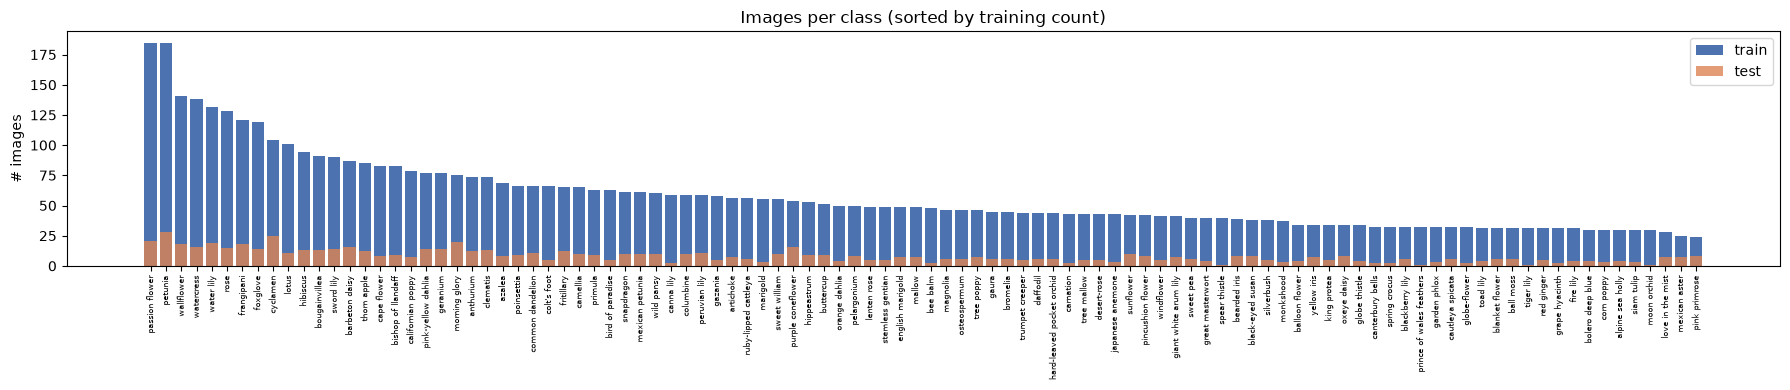

In [20]:
train_counts = np.bincount([y for _, y in train_samples], minlength=NUM_CLASSES)
test_counts = np.bincount([y for _, y in test_samples], minlength=NUM_CLASSES)

print(f"Train images per class: min={train_counts.min()}  median={int(np.median(train_counts))}  "
      f"max={train_counts.max()}  (imbalance ratio {train_counts.max() / max(train_counts.min(), 1):.1f}x)")
print("Rarest classes :", [(CLASS_NAMES[i], int(train_counts[i])) for i in np.argsort(train_counts)[:3]])
print("Largest classes:", [(CLASS_NAMES[i], int(train_counts[i])) for i in np.argsort(train_counts)[-3:][::-1]])

order = np.argsort(train_counts)[::-1]
fig, ax = plt.subplots(figsize=(18, 4))
ax.bar(range(NUM_CLASSES), train_counts[order], color="#4C72B0", label="train")
ax.bar(range(NUM_CLASSES), test_counts[order], color="#DD8452", alpha=0.8, label="test")
ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels([CLASS_NAMES[i] for i in order], rotation=90, fontsize=6)
ax.set_ylabel("# images")
ax.set_title("Images per class (sorted by training count)")
ax.legend()
plt.tight_layout()
plt.show()

In [21]:
# Image size statistics on a random sample (decoding every file would be slow)
rng = random.Random(SEED)
sizes = np.array([Image.open(p).size for p, _ in rng.sample(train_samples, min(300, len(train_samples)))])
print(f"Width : min={sizes[:, 0].min()} median={int(np.median(sizes[:, 0]))} max={sizes[:, 0].max()}")
print(f"Height: min={sizes[:, 1].min()} median={int(np.median(sizes[:, 1]))} max={sizes[:, 1].max()}")
print("-> variable sizes and aspect ratios, so images must be resized/cropped to a fixed input size.")

Width : min=500 median=667 max=919
Height: min=500 median=500 max=863
-> variable sizes and aspect ratios, so images must be resized/cropped to a fixed input size.


### 2.5 Sample images

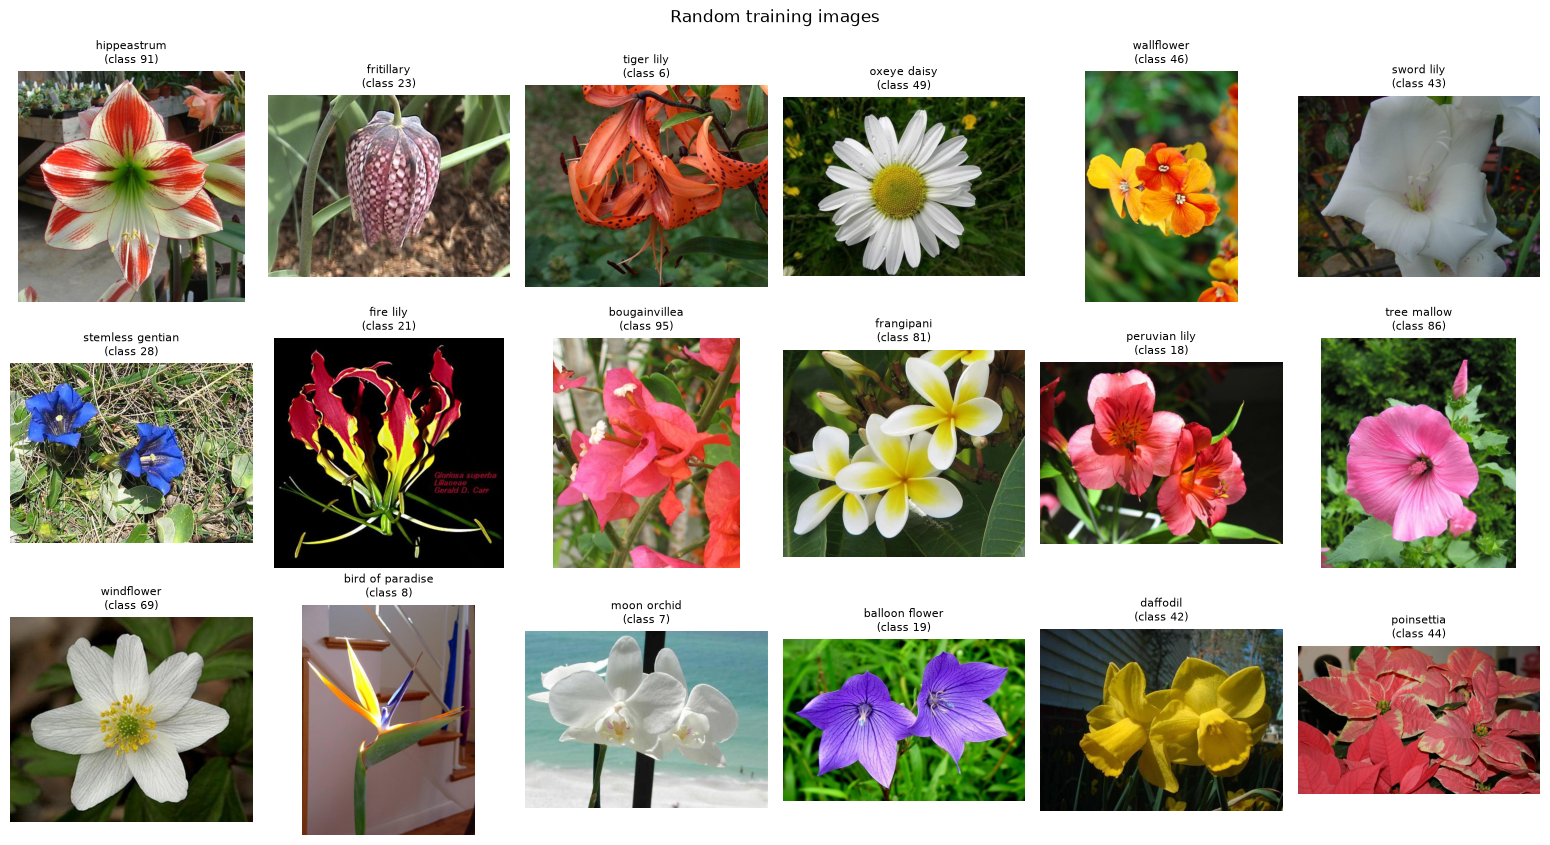

In [22]:
def show_grid(items, ncols=6, size=2.6, title=None):
    # items: list of (PIL image or HxWx3 array, caption, caption_color)
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.1))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, (img, caption, color) in zip(np.atleast_1d(axes).ravel(), items):
        ax.imshow(img)
        ax.set_title(caption, fontsize=8, color=color)
    if title:
        fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


rng = random.Random(SEED)
show_grid([(Image.open(p).convert("RGB"), f"{CLASS_NAMES[y]}\n(class {CLASS_IDS[y]})", "black")
           for p, y in rng.sample(train_samples, 18)], title="Random training images")

## 3. Data Preprocessing

| Step | Train | Val / Test |
|---|---|---|
| Resize / crop | `RandomResizedCrop(224, scale=(0.6, 1))` | `Resize(256)` → `CenterCrop(224)` |
| Augmentation | horizontal flip, ±20° rotation, mild colour jitter | none |
| Normalisation | ImageNet mean/std | ImageNet mean/std |

**Why these choices**

* **224×224 + ImageNet normalisation** matches what the pretrained backbone saw during pre-training.
* **Random crops and scaling** make the model robust to framing and zoom. The minimum crop scale is 0.6 so the flower usually stays in view.
* **Flips and small rotations** are safe because flower identity doesn't depend on orientation.
* **Colour jitter is kept mild** because colour is a key cue for telling species apart. A pink primrose with a heavy hue shift could look like a different species.

> 🧪 **Experimentation point:** try stronger augmentation (`RandAugment`, `TrivialAugmentWide`, Mixup/CutMix, random erasing) or a higher input resolution.

In [23]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 256 / 224)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class FlowerDataset(Dataset):
    # Minimal dataset over a list of (path, label) pairs; label is -1 for unlabeled images.

    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        path, label = self.samples[i]
        img = Image.open(path).convert("RGB")
        return self.transform(img), label


def make_loader(samples, transform, shuffle):
    return DataLoader(FlowerDataset(samples, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")


train_loader = make_loader(train_samples, train_tfms, shuffle=True)
val_loader = make_loader(val_samples, eval_tfms, shuffle=False)
test_loader = make_loader(test_samples, eval_tfms, shuffle=False)

x, y = next(iter(train_loader))
print("Batch:", tuple(x.shape), "| labels:", y[:8].tolist(), "| pixel range after norm:",
      f"[{x.min():.2f}, {x.max():.2f}]")

Batch: (32, 3, 224, 224) | labels: [25, 81, 27, 62, 95, 28, 50, 94] | pixel range after norm: [-2.12, 2.64]


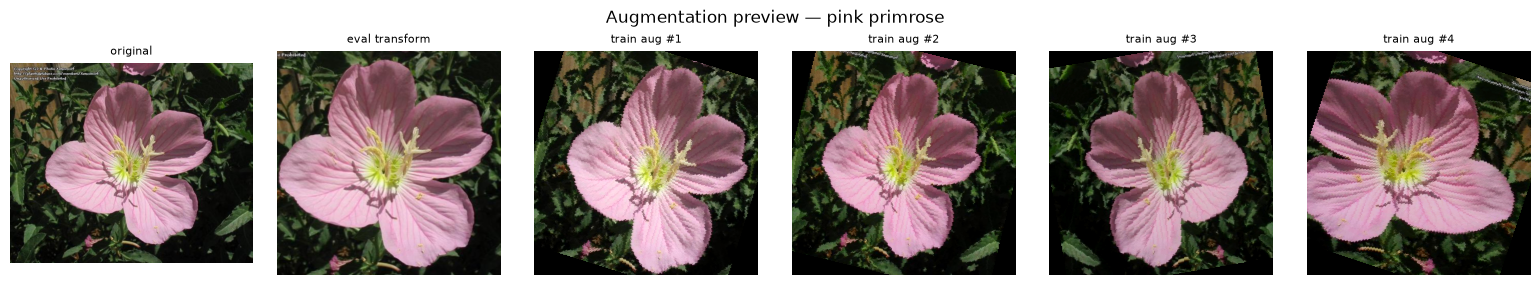

In [24]:
def denormalize(t):
    # CHW normalised tensor -> HWC array in [0, 1] for plotting.
    mean, std = torch.tensor(IMAGENET_MEAN).view(3, 1, 1), torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


# Visual sanity check: the same image passed through the training augmentation several times
path, label = train_samples[0]
original = Image.open(path).convert("RGB")
items = [(original, "original", "black"), (denormalize(eval_tfms(original)), "eval transform", "black")]
items += [(denormalize(train_tfms(original)), f"train aug #{i + 1}", "black") for i in range(4)]
show_grid(items, ncols=6, title=f"Augmentation preview — {CLASS_NAMES[label]}")

## 4. Model Selection

**Baseline: ImageNet-pretrained ResNet-18 with a new 102-way linear head.**

* **Transfer learning fits small data.** With roughly 60 training images per class, the low- and mid-level features learned on ImageNet's 1.2M images (edges, textures, petal-like shapes, colour blobs) transfer very well to flowers. On Oxford 102, even a linear classifier on frozen ImageNet features reaches high accuracy.
* **ResNet-18 is a simple, well-understood baseline.** With 11M parameters and about 1.8 GFLOPs, it trains in reasonable time even on a CPU. The residual architecture is also easy to fine-tune.
* **The design is easy to swap.** `build_model` also supports `resnet50` and `efficientnet_b0`, which are usually more accurate at higher compute cost.

**Two-stage training strategy**

1. **Feature extraction:** freeze the backbone and train only the new head. This is fast and stable, and it avoids destroying pretrained features with large gradients from a randomly initialised head.
2. **Partial fine-tuning:** unfreeze the last backbone block and train it together with the head at a lower learning rate. This adapts high-level features to flower-specific details.

In [25]:
def build_model(name, num_classes):
    # Returns (model, head, last_block): head = new classifier, last_block = deepest backbone stage.
    if name == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    elif name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    elif name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    else:
        raise ValueError(f"Unknown model: {name}")

    if name.startswith("resnet"):
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model, model.fc, model.layer4
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model, model.classifier, model.features[-2:]


def set_trainable(model, modules):
    # Freeze every parameter, then unfreeze only the given modules.
    for p in model.parameters():
        p.requires_grad = False
    for m in modules:
        for p in m.parameters():
            p.requires_grad = True


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return f"{trainable:,} trainable / {total:,} total parameters"


model, head, last_block = build_model(MODEL_NAME, NUM_CLASSES)
model = model.to(DEVICE)
print(MODEL_NAME, "|", count_params(model))

resnet18 | 11,228,838 trainable / 11,228,838 total parameters


## 5. Model Training

* **Loss:** cross-entropy, the standard choice for single-label multi-class classification.
* **Optimizer:** AdamW, which converges quickly with sensible defaults and uses decoupled weight decay.
* **LR schedule:** cosine annealing within each stage, which decays the learning rate smoothly to near zero.
* **Checkpointing:** the weights with the best **validation accuracy** are kept. The test set is never used for model selection.

One subtle detail: when the backbone is frozen, its **BatchNorm layers are kept in eval mode**. Otherwise `model.train()` would quietly overwrite the pretrained running statistics with statistics from small flower batches.

> 🧪 **Experimentation point:** try label smoothing (`nn.CrossEntropyLoss(label_smoothing=0.1)`), class-weighted loss, SGD with momentum, or learning-rate warm-up.

In [26]:
def keep_frozen_bn_in_eval(model):
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


def run_epoch(model, loader, criterion, optimizer=None):
    # One pass over `loader`. Trains if an optimizer is given, otherwise evaluates. Returns (loss, accuracy).
    training = optimizer is not None
    model.train(training)
    if training:
        keep_frozen_bn_in_eval(model)

    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


def fit(model, epochs, optimizer, scheduler, criterion, history, stage, ckpt_path):
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        scheduler.step()

        history.append({"stage": stage, "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va_loss, "val_acc": va_acc})
        is_best = va_acc > max((h["val_acc"] for h in history[:-1]), default=-1)
        if is_best:
            torch.save(model.state_dict(), ckpt_path)
        print(f"[{stage}] epoch {epoch}/{epochs} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - t0:.0f}s" + ("  *best*" if is_best else ""))


criterion = nn.CrossEntropyLoss()
history = []
CKPT_PATH = OUTPUT_DIR / f"best_{MODEL_NAME}.pt"

### 5.1 Stage 1 — train the classifier head (backbone frozen)

In [27]:
set_trainable(model, [head])
print(count_params(model))

optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=HEAD_LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=HEAD_EPOCHS)
fit(model, HEAD_EPOCHS, optimizer, scheduler, criterion, history, "head", CKPT_PATH)

52,326 trainable / 11,228,838 total parameters
[head] epoch 1/5 | train loss 3.110 acc 0.376 | val loss 1.892 acc 0.633 | 223s  *best*
[head] epoch 2/5 | train loss 1.497 acc 0.736 | val loss 1.228 acc 0.775 | 216s  *best*
[head] epoch 3/5 | train loss 1.027 acc 0.825 | val loss 1.015 acc 0.801 | 220s  *best*
[head] epoch 4/5 | train loss 0.863 acc 0.860 | val loss 0.903 acc 0.819 | 217s  *best*
[head] epoch 5/5 | train loss 0.782 acc 0.871 | val loss 0.865 acc 0.852 | 240s  *best*


### 5.2 Stage 2 — fine-tune the last backbone block

This stage starts from the best stage-1 checkpoint. It unfreezes the deepest stage of the backbone and uses a 10× smaller learning rate so the pretrained features are adjusted gently rather than overwritten.

> 🧪 **Experimentation point:** unfreeze more layers, use discriminative learning rates (smaller for earlier layers), or train for longer. This is usually where the largest accuracy gains come from.

In [28]:
if FINETUNE_EPOCHS > 0:
    model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
    set_trainable(model, [last_block, head])
    print(count_params(model))

    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=FINETUNE_LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINETUNE_EPOCHS)
    fit(model, FINETUNE_EPOCHS, optimizer, scheduler, criterion, history, "finetune", CKPT_PATH)
else:
    print("Fine-tuning skipped (FINETUNE_EPOCHS = 0).")

8,446,054 trainable / 11,228,838 total parameters
[finetune] epoch 1/3 | train loss 0.506 acc 0.883 | val loss 0.297 acc 0.932 | 327s  *best*
[finetune] epoch 2/3 | train loss 0.200 acc 0.960 | val loss 0.206 acc 0.951 | 356s  *best*
[finetune] epoch 3/3 | train loss 0.125 acc 0.980 | val loss 0.183 acc 0.953 | 314s  *best*


### 5.3 Learning curves

What to look for:

* A large gap between training and validation accuracy suggests **overfitting**. Try more augmentation or regularisation.
* If both curves are still rising at the end, the model is **under-trained**. Add epochs.

Note that training accuracy is measured on *augmented* images, so it can sit slightly below validation accuracy early on.

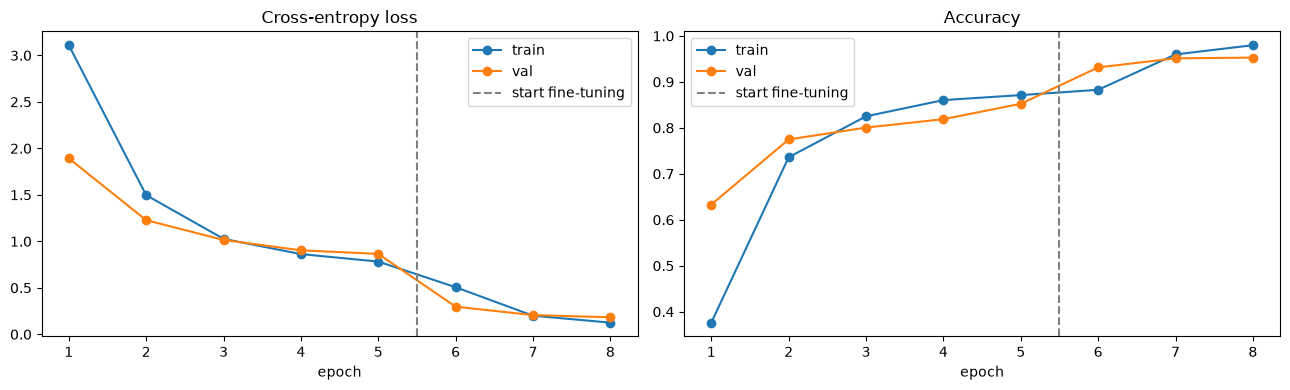

Best val accuracy: 0.9528 (stage: finetune)


In [29]:
epochs_axis = np.arange(1, len(history) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["loss", "acc"]):
    ax.plot(epochs_axis, [h[f"train_{metric}"] for h in history], "o-", label="train")
    ax.plot(epochs_axis, [h[f"val_{metric}"] for h in history], "o-", label="val")
    if FINETUNE_EPOCHS > 0:
        ax.axvline(HEAD_EPOCHS + 0.5, color="gray", ls="--", label="start fine-tuning")
    ax.set_xlabel("epoch")
    ax.set_title({"loss": "Cross-entropy loss", "acc": "Accuracy"}[metric])
    ax.legend()
plt.tight_layout()
plt.show()

best = max(history, key=lambda h: h["val_acc"])
print(f"Best val accuracy: {best['val_acc']:.4f} (stage: {best['stage']})")

## 6. Evaluation on the held-out test set

The best checkpoint (selected by validation accuracy) is reloaded and evaluated **once** on the test set.

| Metric | Why it is reported |
|---|---|
| Accuracy / Top-5 accuracy | Headline metrics. Top-5 shows whether the correct class is at least among the top candidates. |
| Macro precision / recall / F1 | Every class counts equally, so weak rare classes can't hide behind frequent ones. |
| Per-class F1 | Shows *which* species are hard. |
| Confusion matrix | Shows *which classes are mistaken for which*. |

In [30]:
@torch.no_grad()
def predict(model, loader):
    # Returns (probabilities [N, C], labels [N]) as numpy arrays.
    model.eval()
    all_probs, all_labels = [], []
    for x, y in loader:
        all_probs.append(torch.softmax(model(x.to(DEVICE)), dim=1).cpu())
        all_labels.append(y)
    return torch.cat(all_probs).numpy(), torch.cat(all_labels).numpy()


def confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)   # rows = true class, columns = predicted class
    return cm


def per_class_metrics(cm):
    tp = np.diag(cm).astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        precision = np.nan_to_num(tp / cm.sum(axis=0))
        recall = np.nan_to_num(tp / cm.sum(axis=1))
        f1 = np.nan_to_num(2 * precision * recall / (precision + recall))
    return precision, recall, f1


model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
test_probs, y_true = predict(model, test_loader)
y_pred = test_probs.argmax(1)
top5_hit = (np.argsort(-test_probs, axis=1)[:, :5] == y_true[:, None]).any(1)

cm = confusion_matrix(y_true, y_pred, NUM_CLASSES)
precision, recall, f1 = per_class_metrics(cm)
present = cm.sum(axis=1) > 0                # only average over classes that occur in the test set
support = cm.sum(axis=1)

print(f"Test images      : {len(y_true)}  ({test_source})")
print(f"Accuracy         : {(y_pred == y_true).mean():.4f}")
print(f"Top-5 accuracy   : {top5_hit.mean():.4f}")
print(f"Macro precision  : {precision[present].mean():.4f}")
print(f"Macro recall     : {recall[present].mean():.4f}")
print(f"Macro F1         : {f1[present].mean():.4f}")
print(f"Weighted F1      : {np.average(f1, weights=support):.4f}")

Test images      : 818  (valid/ (used as held-out test set))
Accuracy         : 0.9621
Top-5 accuracy   : 0.9939
Macro precision  : 0.9499
Macro recall     : 0.9649
Macro F1         : 0.9522
Weighted F1      : 0.9626


In [31]:
def print_class_table(indices, title):
    print(title)
    print(f"{'class':<28}{'precision':>10}{'recall':>9}{'f1':>7}{'support':>9}{'n_train':>9}")
    for i in indices:
        print(f"{CLASS_NAMES[i][:27]:<28}{precision[i]:>10.3f}{recall[i]:>9.3f}{f1[i]:>7.3f}"
              f"{support[i]:>9d}{train_counts[i]:>9d}")
    print()


ranked = [i for i in np.argsort(f1) if present[i]]
print_class_table(ranked[:10], "10 hardest classes (lowest F1):")
print_class_table(ranked[::-1][:5], "5 easiest classes (highest F1):")
print(f"Classes with perfect F1: {int((f1[present] == 1).sum())} / {int(present.sum())}")

10 hardest classes (lowest F1):
class                        precision   recall     f1  support  n_train
sweet pea                        1.000    0.500  0.667        6       40
moon orchid                      0.500    1.000  0.667        1       30
carnation                        0.500    1.000  0.667        2       43
siam tulip                       0.667    0.667  0.667        3       30
japanese anemone                 0.667    0.667  0.667        3       43
ball moss                        0.714    0.833  0.769        6       31
tree mallow                      0.625    1.000  0.769        5       43
spring crocus                    0.667    1.000  0.800        2       32
lenten rose                      0.714    1.000  0.833        5       49
giant white arum lily            0.857    0.857  0.857        7       41

5 easiest classes (highest F1):
class                        precision   recall     f1  support  n_train
blackberry lily                  1.000    1.000  1.000     

### 6.1 Confusion matrix

With 102 classes, the full matrix is mostly diagonal. It is row-normalised, so each cell shows the fraction of a true class predicted as each class, and off-diagonal spots stand out as systematic confusions. A zoomed view of the classes involved in the most errors follows.

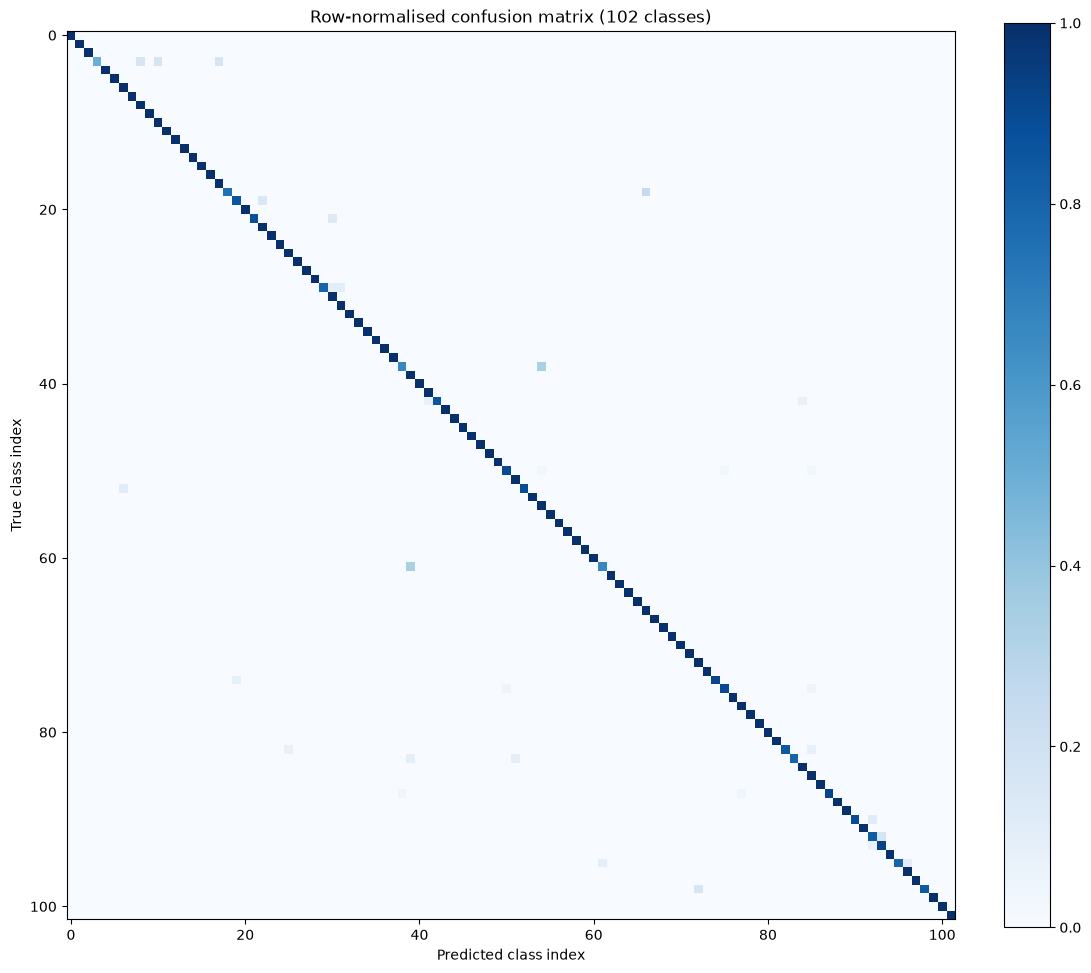

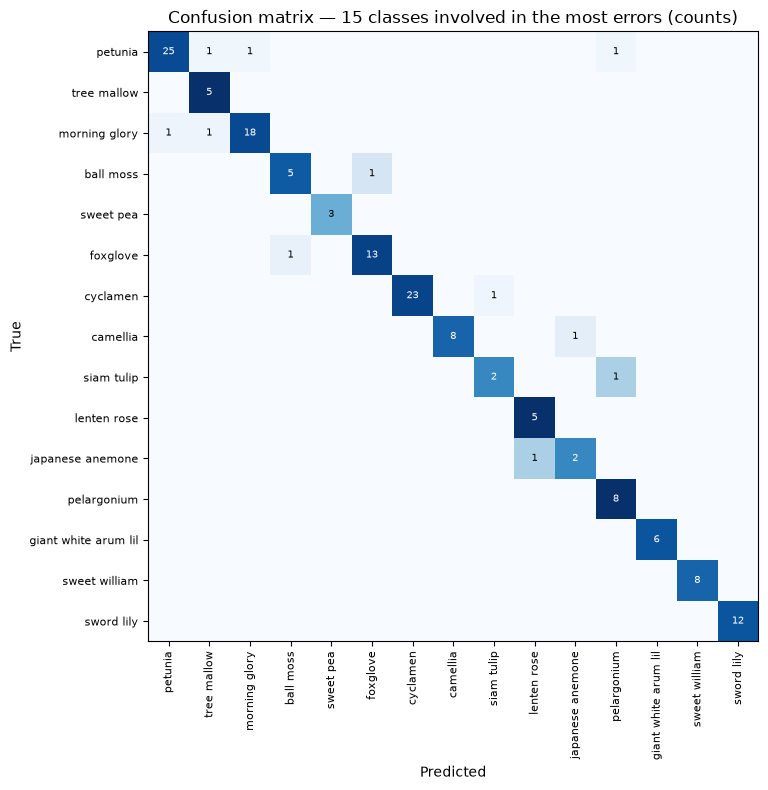

In [32]:
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xlabel("Predicted class index")
ax.set_ylabel("True class index")
ax.set_title("Row-normalised confusion matrix (102 classes)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# Zoom in on the classes involved in the most errors
errors = cm - np.diag(np.diag(cm))
involved = np.argsort(errors.sum(0) + errors.sum(1))[::-1][:15]
sub = cm_norm[np.ix_(involved, involved)]
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(sub, cmap="Blues", vmin=0, vmax=1)
labels = [CLASS_NAMES[i][:20] for i in involved]
ax.set_xticks(range(len(involved)))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(involved)))
ax.set_yticklabels(labels, fontsize=8)
for r in range(len(involved)):
    for c in range(len(involved)):
        if cm[involved[r], involved[c]] > 0:
            ax.text(c, r, cm[involved[r], involved[c]], ha="center", va="center", fontsize=7,
                    color="white" if sub[r, c] > 0.5 else "black")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix — 15 classes involved in the most errors (counts)")
plt.tight_layout()
plt.show()

### 6.2 Correct and incorrect predictions

787 correct, 31 incorrect


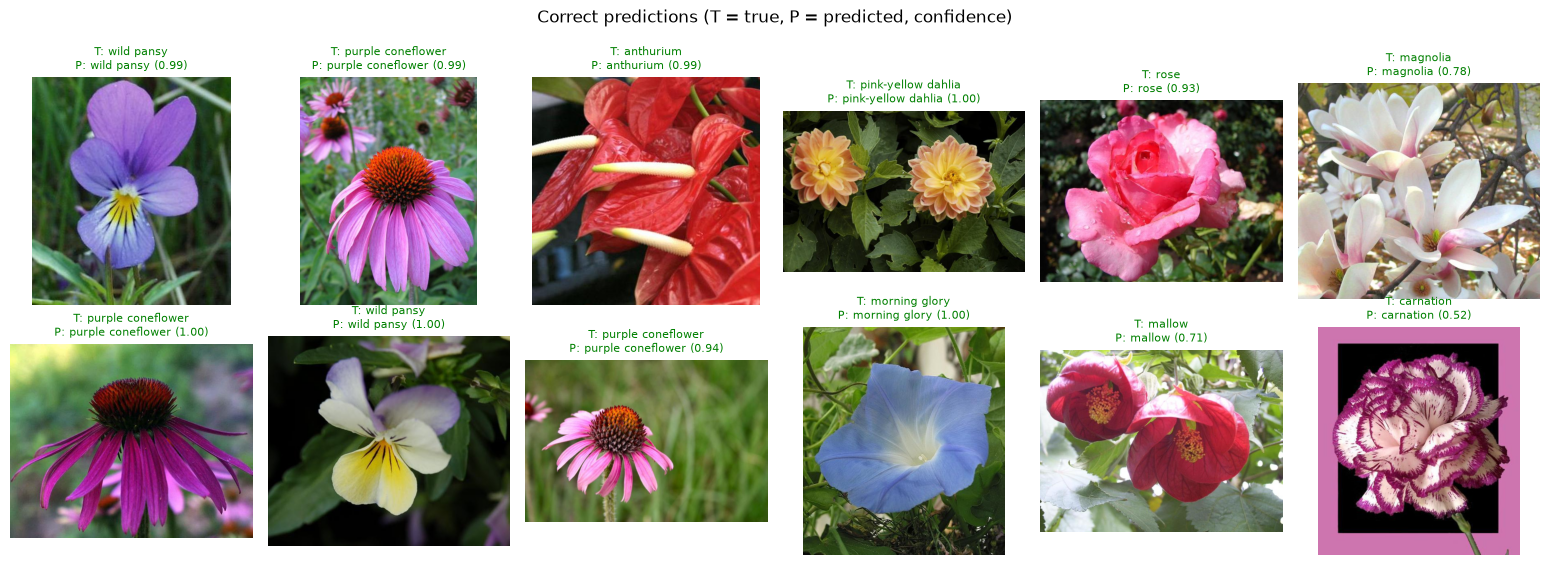

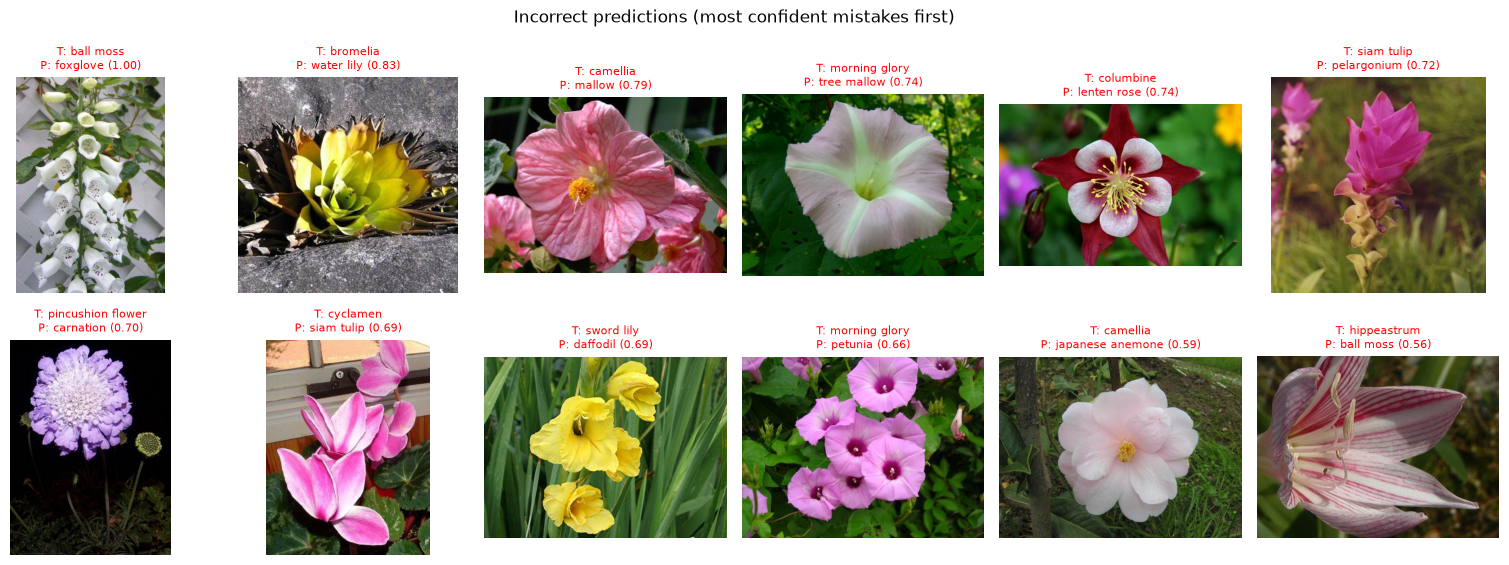

In [33]:
def prediction_items(indices):
    items = []
    for i in indices:
        path, _ = test_samples[i]
        ok = y_pred[i] == y_true[i]
        caption = f"T: {CLASS_NAMES[y_true[i]][:18]}\nP: {CLASS_NAMES[y_pred[i]][:18]} ({test_probs[i, y_pred[i]]:.2f})"
        items.append((Image.open(path).convert("RGB"), caption, "green" if ok else "red"))
    return items


rng = np.random.default_rng(SEED)
correct_idx = np.flatnonzero(y_pred == y_true)
wrong_idx = np.flatnonzero(y_pred != y_true)
print(f"{len(correct_idx)} correct, {len(wrong_idx)} incorrect")

show_grid(prediction_items(rng.choice(correct_idx, min(12, len(correct_idx)), replace=False)),
          title="Correct predictions (T = true, P = predicted, confidence)")
if len(wrong_idx):
    # Most confident mistakes first: these are the most informative errors
    worst = wrong_idx[np.argsort(-test_probs[wrong_idx, y_pred[wrong_idx]])][:12]
    show_grid(prediction_items(worst), title="Incorrect predictions (most confident mistakes first)")

## 7. Error Analysis

Three questions guide the analysis:

1. **Which class pairs are confused most often?**
2. **Do the mistakes have a pattern?** For example, are they low-confidence, or concentrated in classes with little training data?
3. **What do the confused classes actually look like side by side?**

In [34]:
pairs = [(errors[t, p], t, p) for t in range(NUM_CLASSES) for p in range(NUM_CLASSES) if errors[t, p] > 0]
pairs.sort(reverse=True)

print(f"{'true class':<28}{'predicted as':<28}{'count':>6}{'% of true class':>17}")
for count, t, p in pairs[:15]:
    print(f"{CLASS_NAMES[t][:27]:<28}{CLASS_NAMES[p][:27]:<28}{count:>6}{100 * count / support[t]:>16.0f}%")

# Pairs confused in BOTH directions point at genuinely similar-looking classes
mutual = sorted({tuple(sorted((t, p))) for _, t, p in pairs if errors[p, t] > 0})
print("\nMutually confused pairs:", [(CLASS_NAMES[a], CLASS_NAMES[b]) for a, b in mutual[:10]] or "none")

true class                  predicted as                 count  % of true class
bromelia                    water lily                       1              17%
camellia                    mallow                           1              10%
camellia                    japanese anemone                 1              10%
foxglove                    ball moss                        1               7%
ball moss                   foxglove                         1              17%
hippeastrum                 ball moss                        1              11%
cyclamen                    lotus                            1               4%
cyclamen                    siam tulip                       1               4%
columbine                   wild pansy                       1              10%
columbine                   lenten rose                      1              10%
hibiscus                    tree mallow                      1               8%
hibiscus                    corn poppy  

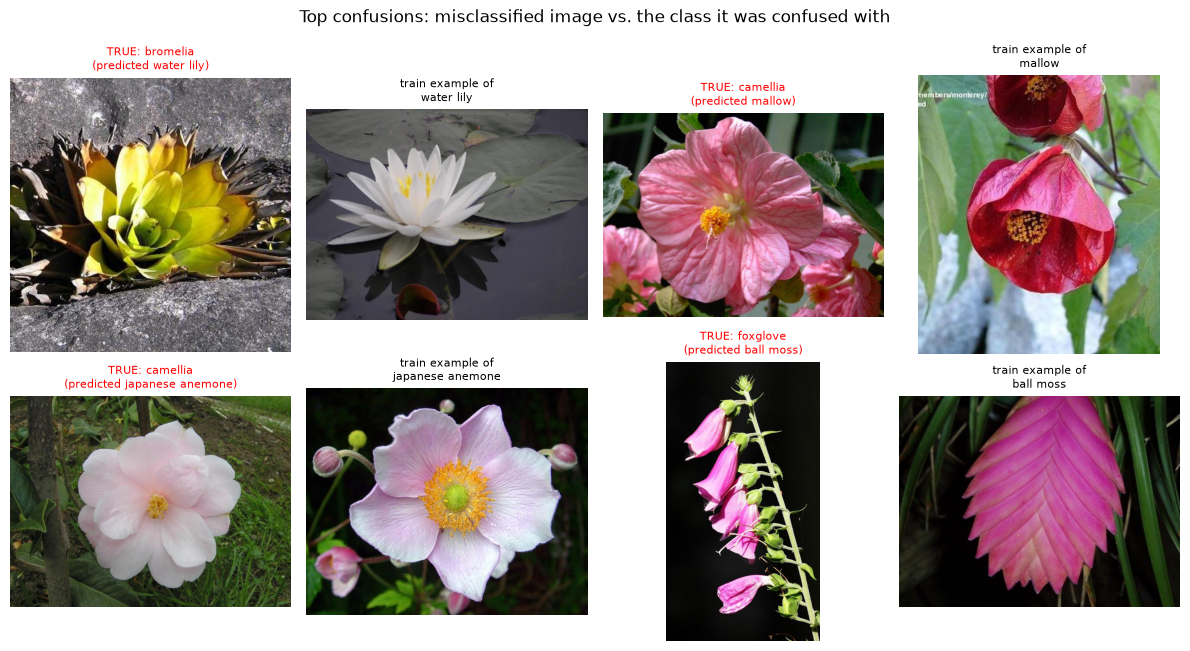

In [35]:
# Side by side: misclassified test image | a training image of the class it was mistaken for
train_by_class = defaultdict(list)
for p, y in train_samples:
    train_by_class[y].append(p)

items = []
for _, t, p in pairs[:4]:
    i = next(i for i in wrong_idx if y_true[i] == t and y_pred[i] == p)
    items.append((Image.open(test_samples[i][0]).convert("RGB"), f"TRUE: {CLASS_NAMES[t]}\n(predicted {CLASS_NAMES[p]})", "red"))
    items.append((Image.open(train_by_class[p][0]).convert("RGB"), f"train example of\n{CLASS_NAMES[p]}", "black"))
if items:
    show_grid(items, ncols=4, size=3, title="Top confusions: misclassified image vs. the class it was confused with")

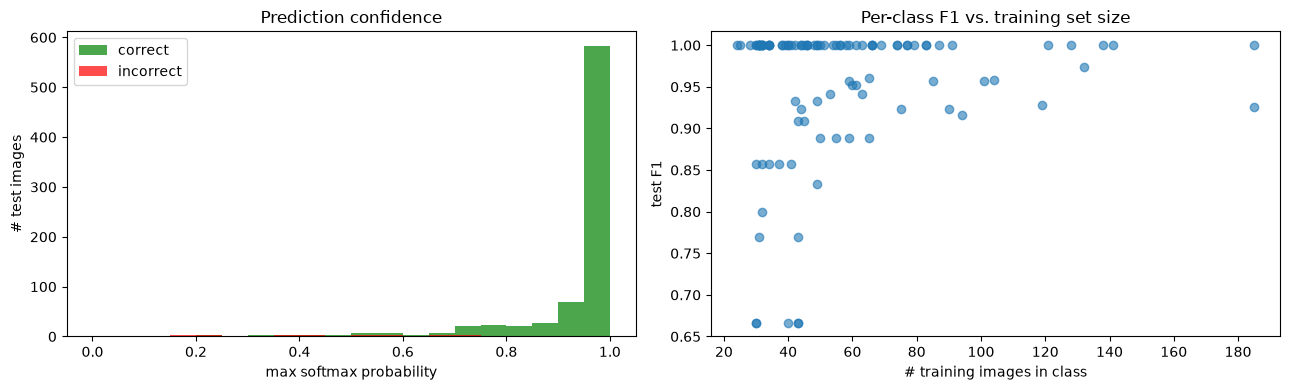

Mean confidence - correct: 0.938 | incorrect: 0.498
Correlation(training count, F1): 0.16
Accuracy on predictions with confidence >= 0.5: 0.980 (covers 96% of images)
Accuracy on predictions with confidence >= 0.8: 0.997 (covers 86% of images)


In [36]:
conf = test_probs.max(1)
correct_mask = y_pred == y_true

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(0, 1, 21)
axes[0].hist(conf[correct_mask], bins=bins, alpha=0.7, label="correct", color="green")
axes[0].hist(conf[~correct_mask], bins=bins, alpha=0.7, label="incorrect", color="red")
axes[0].set_xlabel("max softmax probability")
axes[0].set_ylabel("# test images")
axes[0].set_title("Prediction confidence")
axes[0].legend()

axes[1].scatter(train_counts[present], f1[present], alpha=0.6)
axes[1].set_xlabel("# training images in class")
axes[1].set_ylabel("test F1")
axes[1].set_title("Per-class F1 vs. training set size")
plt.tight_layout()
plt.show()

if correct_mask.any() and (~correct_mask).any():
    print(f"Mean confidence - correct: {conf[correct_mask].mean():.3f} | incorrect: {conf[~correct_mask].mean():.3f}")
if train_counts[present].std() > 0 and f1[present].std() > 0:
    print(f"Correlation(training count, F1): {np.corrcoef(train_counts[present], f1[present])[0, 1]:.2f}")
for thr in (0.5, 0.8):
    keep = conf >= thr
    if keep.any():
        print(f"Accuracy on predictions with confidence >= {thr}: {correct_mask[keep].mean():.3f} "
              f"(covers {keep.mean():.0%} of images)")

### 7.1 Interpreting the errors

Use the tables and plots above to check which of these typical causes apply to your run:

| Possible cause | How to recognise it | Possible fix |
|---|---|---|
| **Visually similar species** (fine-grained classes, such as related lilies, dahlias, poppies or daisy-like flowers) | Pairs confused in *both* directions. The side-by-side images look alike to a human too. | Higher resolution, fine-tuning more layers, a stronger backbone |
| **Colour as a misleading cue** (the same colour across different species, or one species in several colours) | Mistakes between classes of the same colour but different shape | Rely less on colour (stronger colour jitter), more shape-sensitive features |
| **Framing and scale** (extreme close-ups, distant shots, several flowers, cluttered foliage) | Wrong predictions on images where the flower is small or cut off | Multi-crop / test-time augmentation, wider `RandomResizedCrop` scale range |
| **Too little training data** | Positive correlation between training count and F1 | Class-balanced sampling or loss weighting, targeted augmentation |
| **Under-fitting** | Many low-confidence mistakes, validation curve still rising | More epochs, unfreeze more layers |
| **Over-confident errors** | Wrong predictions with confidence > 0.9 | Label smoothing, check those images for label noise |

The confidence analysis also gives a practical option: predictions above a confidence threshold are much more reliable, so low-confidence images could be flagged for human review.

## 7.2 Inference on the unlabeled images

This section runs only if the dataset contains an unlabeled split (such as the flat `test/` folder). Predictions are written to a CSV, and a few are shown for a visual spot-check. Accuracy can't be computed here because these images have no labels.

Saved 819 predictions to outputs\unlabeled_predictions.csv
Predicted class distribution (top 5): [('water lily', 29), ('passion flower', 26), ('petunia', 25), ('wallflower', 22), ('clematis', 18)]


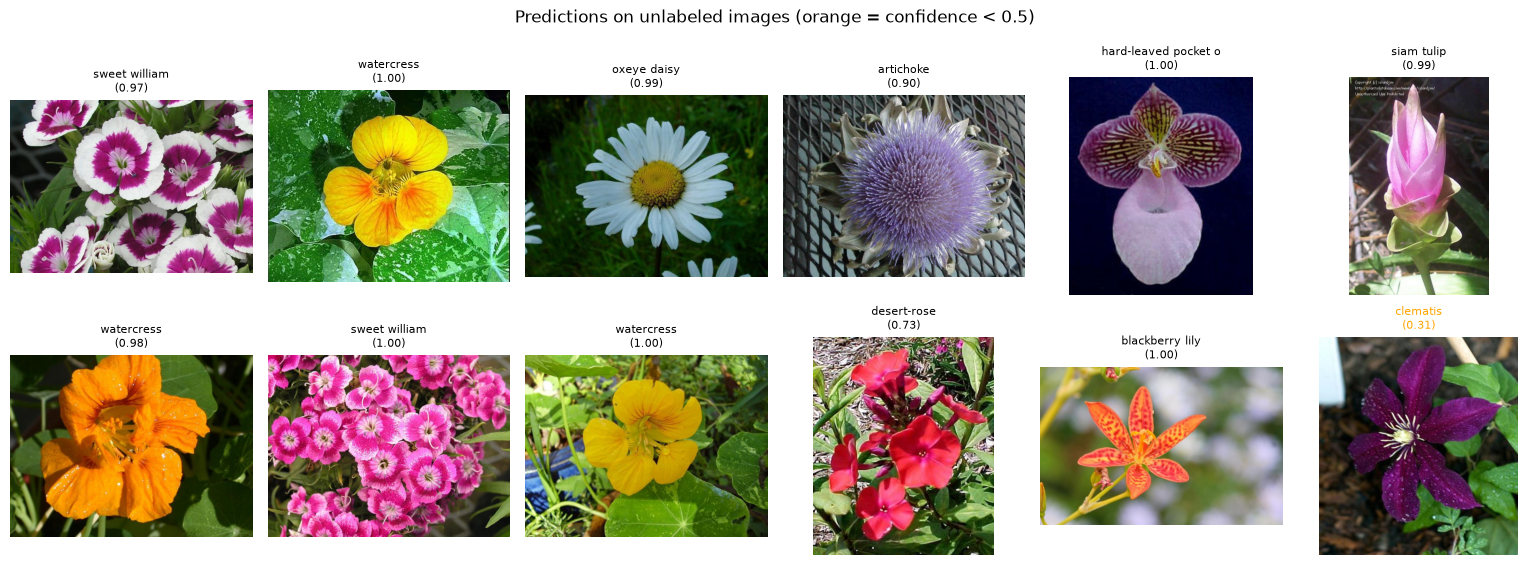

In [37]:
if unlabeled_samples:
    unl_probs, _ = predict(model, make_loader(unlabeled_samples, eval_tfms, shuffle=False))
    unl_pred = unl_probs.argmax(1)

    out_csv = OUTPUT_DIR / "unlabeled_predictions.csv"
    with open(out_csv, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["filename", "class_id", "class_name", "confidence"])
        for (path, _), k, pr in zip(unlabeled_samples, unl_pred, unl_probs):
            writer.writerow([path.name, CLASS_IDS[k], CLASS_NAMES[k], f"{pr[k]:.4f}"])
    print(f"Saved {len(unlabeled_samples)} predictions to {out_csv}")
    print("Predicted class distribution (top 5):",
          [(CLASS_NAMES[k], c) for k, c in Counter(unl_pred.tolist()).most_common(5)])

    rng = np.random.default_rng(SEED)
    pick = rng.choice(len(unlabeled_samples), min(12, len(unlabeled_samples)), replace=False)
    show_grid([(Image.open(unlabeled_samples[i][0]).convert("RGB"),
                f"{CLASS_NAMES[unl_pred[i]][:20]}\n({unl_probs[i, unl_pred[i]]:.2f})",
                "black" if unl_probs[i].max() >= 0.5 else "orange") for i in pick],
              title="Predictions on unlabeled images (orange = confidence < 0.5)")
else:
    print("No unlabeled split found.")

## 8. Next Steps / Improvements

The baseline above is a complete, reproducible pipeline. Below are suggested improvements, ordered roughly by **expected gain per unit of effort**. Change **one thing at a time** and compare validation metrics against the baseline.

| # | Improvement | Where to change it | Notes |
|---|---|---|---|
| 1 | **Deeper fine-tuning.** Unfreeze `layer3`/`layer4` (or the whole network) with discriminative learning rates, and train for more epochs. | §5.2 | Usually the largest single gain on Oxford 102 |
| 2 | **Stronger backbone.** Try `resnet50`, `efficientnet_b0/b3`, ConvNeXt-T, or ViT/DINOv2/CLIP features. | `MODEL_NAME`, `build_model` | Modern self-supervised features reach high-90s accuracy on this dataset |
| 3 | **Stronger augmentation.** Try `TrivialAugmentWide`/`RandAugment`, `RandomErasing`, Mixup/CutMix. | `train_tfms` | Helps most once more layers are unfrozen and overfitting appears |
| 4 | **Regularisation.** Try label smoothing (0.1), dropout before the head, early stopping. | `criterion`, `build_model` | Also tends to reduce over-confident errors |
| 5 | **Hyperparameter tuning.** Tune learning rate (sweep 1e-4 … 3e-3), batch size, weight decay, LR warm-up, OneCycle schedule. | Config cell | Use the validation split only, never the test set |
| 6 | **Class imbalance.** Try `WeightedRandomSampler` or class-weighted cross-entropy. | `make_loader`, `criterion` | Check whether macro F1 improves on rare classes |
| 7 | **Higher resolution.** Try 288–384 px. | `IMG_SIZE` | Fine-grained details (petal texture, stamen) become visible; costs compute |
| 8 | **Test-time augmentation.** Average predictions over flips and multiple crops. | `predict` | Cheap gain of about 0.5–1% at inference time |
| 9 | **Ensembling.** Average the probabilities of 2–3 different architectures. | after §6 | Reliable final boost |
| 10 | **Engineering.** Mixed precision (`torch.autocast`), move the Dataset into a `.py` module so `NUM_WORKERS > 0` works on Windows, add experiment tracking (TensorBoard/W&B). | Config cell, §3 | Faster iterations |

**Reproducibility tip:** after each experiment, save the config, the `history` list and the test metrics so that runs can be compared side by side.